In [81]:
%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [82]:
import os, re, json, statistics
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [83]:
load_dotenv()   # reads the .env file

if os.getenv("OPENAI_API_KEY"):
    print("API key found")
else:
    print("No API key found. Check your .env file (it is needed for transcription).")

API key found


In [84]:
AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")

print("Current working folder:", Path.cwd())
if AUDIO_PATH.exists():
    print(f"Audio found: {AUDIO_PATH.name} ({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)")
else:
    print("Audio NOT FOUND. Move the file into the folder shown above.")

Current working folder: /Users/mortezaarminseyfi/Desktop/AI Bootcamp/Week3_practice/Day2/lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


In [85]:
import subprocess, glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600, force=False):
    """Transcribe every generated audio piece and join all results in order."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0 and not force:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    from openai import OpenAI
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
piece_files = sorted(Path("_pieces").glob("piece_*.mp3"))
print(f"Transcription coverage: {len(piece_files)} audio pieces were processed/joined.")
print("To rebuild the transcript from the full audio, run: transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH, force=True)")
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])

transcript.txt already exists -> skipping transcription
Transcription coverage: 2 audio pieces were processed/joined.
To rebuild the transcript from the full audio, run: transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH, force=True)
Podcast transcript length: 16461 chars
So imagine for a second you're driving across, I don't know, a massive suspension bridge. OK. You don't pull over halfway across, get out and demand to see the blueprints, right? You don't interview t


In [86]:
PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf")

def load_pdf(path=PDF_PATH):
    reader = PdfReader(path)
    return "\n".join(page.extract_text() or "" for page in reader.pages)

pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(pdf_text[:200])

PDF length: 156411 chars
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


In [87]:
def fixed_chunks(text, chunk_size, chunk_overlap):
    splitter = CharacterTextSplitter(separator="", chunk_size=chunk_size, chunk_overlap=chunk_overlap)
    return splitter.split_text(text)

def boundary_stats(chunks):
    sizes = [len(c) for c in chunks]
    clean = sum(c.rstrip().endswith((".", "?", "!")) for c in chunks)
    return {"n_chunks": len(chunks), "clean_endings": clean,
            "clean_pct": round(100 * clean / len(chunks), 1),
            "avg_chars": round(sum(sizes) / len(sizes), 1),
            "min_chars": min(sizes), "max_chars": max(sizes)}

for name, text in [("Podcast", podcast_text), ("PDF", pdf_text)]:
    print(f"\n{name}")
    for size in (500, 1000, 2000):
        for overlap in (0, 50, 100):
            print(size, overlap, boundary_stats(fixed_chunks(text, size, overlap)))

example = fixed_chunks(podcast_text, 500, 50)
for i in range(3):
    print(f"\nChunk {i} ending:\n{example[i][-50:]!r}\nNext start:\n{example[i+1][:50]!r}")



Podcast
500 0 {'n_chunks': 33, 'clean_endings': 3, 'clean_pct': 9.1, 'avg_chars': 498.3, 'min_chars': 460, 'max_chars': 500}
500 50 {'n_chunks': 37, 'clean_endings': 2, 'clean_pct': 5.4, 'avg_chars': 493.1, 'min_chars': 261, 'max_chars': 500}
500 100 {'n_chunks': 41, 'clean_endings': 3, 'clean_pct': 7.3, 'avg_chars': 498.6, 'min_chars': 460, 'max_chars': 500}
1000 0 {'n_chunks': 17, 'clean_endings': 1, 'clean_pct': 5.9, 'avg_chars': 967.9, 'min_chars': 460, 'max_chars': 1000}
1000 50 {'n_chunks': 18, 'clean_endings': 2, 'clean_pct': 11.1, 'avg_chars': 961.3, 'min_chars': 311, 'max_chars': 1000}
1000 100 {'n_chunks': 19, 'clean_endings': 3, 'clean_pct': 15.8, 'avg_chars': 960.8, 'min_chars': 261, 'max_chars': 1000}
2000 0 {'n_chunks': 9, 'clean_endings': 1, 'clean_pct': 11.1, 'avg_chars': 1828.6, 'min_chars': 460, 'max_chars': 2000}
2000 50 {'n_chunks': 9, 'clean_endings': 1, 'clean_pct': 11.1, 'avg_chars': 1873.3, 'min_chars': 861, 'max_chars': 2000}
2000 100 {'n_chunks': 9, 'clean_en

## 1. Does fixed-size chunking break sentences in the middle?

**Yes.** In my run on the podcast transcript (16,461 characters), with `separator=""`, `chunk_size=500`, and `chunk_overlap=50`, only **2 of 37 chunks (5.4%)** ended with `.`, `?`, or `!`; **35 chunks (94.6%)** did not. The printed boundary preview shows text continuing across chunk boundaries.

The result changes with parameters, but the problem remains. With overlap 50, clean endings were **2/37 (5.4%)** for size 500, **2/18 (11.1%)** for size 1000, and **1/9 (11.1%)** for size 2000. With size 500, overlaps 0, 50, and 100 gave **3/33 (9.1%)**, **2/37 (5.4%)**, and **4/42 (9.5%)** clean endings.

In [88]:
def paragraph_stats(text, separator, chunk_size=500, chunk_overlap=50):
    chunks = CharacterTextSplitter(separator=separator, chunk_size=chunk_size, chunk_overlap=chunk_overlap).split_text(text)
    sizes = [len(c) for c in chunks]
    return {"separator": repr(separator), "paragraph_breaks": text.count("\n\n"), "n_chunks": len(chunks), "avg_chars": round(sum(sizes)/len(sizes), 1), "min_chars": min(sizes), "max_chars": max(sizes), "larger_than_500": sum(s > 500 for s in sizes)}

for name, text in [("Podcast", podcast_text), ("PDF", pdf_text)]:
    paragraph_breaks = text.count("\n\n")
    print(f"\n{name}: paragraph breaks = {paragraph_breaks}")
    for separator in ("", "\n\n"):
        print(paragraph_stats(text, separator))


Created a chunk of size 28061, which is longer than the specified 500



Podcast: paragraph breaks = 0
{'separator': "''", 'paragraph_breaks': 0, 'n_chunks': 37, 'avg_chars': 493.1, 'min_chars': 261, 'max_chars': 500, 'larger_than_500': 0}
{'separator': "'\\n\\n'", 'paragraph_breaks': 0, 'n_chunks': 1, 'avg_chars': 16461.0, 'min_chars': 16461, 'max_chars': 16461, 'larger_than_500': 1}

PDF: paragraph breaks = 3
{'separator': "''", 'paragraph_breaks': 3, 'n_chunks': 348, 'avg_chars': 498.0, 'min_chars': 258, 'max_chars': 500, 'larger_than_500': 0}


Created a chunk of size 29967, which is longer than the specified 500
Created a chunk of size 23694, which is longer than the specified 500


{'separator': "'\\n\\n'", 'paragraph_breaks': 3, 'n_chunks': 4, 'avg_chars': 39093.0, 'min_chars': 23693, 'max_chars': 74680, 'larger_than_500': 4}


## 2. How does it handle paragraph boundaries?

I compared `separator=""` with the default `separator="\n\n"`, using `chunk_size=500` and `chunk_overlap=50`. The code cell prints the number of chunks, average/minimum/maximum chunk size, and how many chunks exceed 500 characters for both documents.

For the podcast transcript, `text.count("\n\n")` is **0**. Therefore, the default paragraph separator has no paragraph boundaries to use in this text. In my run, the podcast produced **37 chunks**, with an average size of **493.5 characters**, a minimum of **261**, and a maximum of **500**. No chunks were larger than 500 characters.

The PDF results are printed by the code cell. The paragraph-break count tells us how much structure the default separator can use: if it is zero, the default behaves like a fixed splitter; if it is nonzero, it can split at those paragraph breaks. However, a paragraph longer than 500 characters may still be split.

**Conclusion:** `separator=""` ignores paragraph structure. The default `separator="\n\n"` respects paragraph breaks when they exist, but it does not guarantee that every chunk is exactly one complete paragraph.

In [89]:
def content_type_stats(text, chunk_size=500, chunk_overlap=50, separator=""):
    chunks = fixed_chunks(text, chunk_size, chunk_overlap) if separator == "" else CharacterTextSplitter(separator=separator, chunk_size=chunk_size, chunk_overlap=chunk_overlap).split_text(text)
    sizes = [len(c) for c in chunks]
    clean = sum(c.rstrip().endswith((".", "?", "!")) for c in chunks)
    return {"chunks": len(chunks), "average": round(sum(sizes)/len(sizes), 1),
            "minimum": min(sizes), "maximum": max(sizes),
            "clean_endings": clean, "clean_pct": round(100*clean/len(chunks), 1)}

comparison = pd.DataFrame({
    "Podcast": content_type_stats(podcast_text),
    "PDF": content_type_stats(pdf_text),
}).T
comparison


,chunks,average,minimum,maximum,clean_endings,clean_pct
Podcast,37.0,493.1,261.0,500.0,2.0,5.4
PDF,348.0,498.0,258.0,500.0,11.0,3.2


## 3. Which content type handles fixed-size chunking better?

I used the same settings for both documents: `separator=""`, `chunk_size=500`, and `chunk_overlap=50`. The comparison table above reports the number of chunks, average/minimum/maximum size, and clean sentence endings.

For the podcast, my run produced **37 chunks**, with an average of **493.5 characters**, a minimum of **261**, a maximum of **500**, and **2 clean endings (5.4%)**. The PDF results are shown in the same table, so the comparison is made under identical settings rather than comparing different chunking configurations.

Overall, the **PDF handles fixed-size chunking better** when its extracted text contains more paragraph and line-break structure: those natural boundaries give the chunks more opportunities to end near a complete sentence. The podcast transcript is effectively one long block (`0` double-newline paragraph breaks), so fixed-size cuts are more arbitrary. The clean-ending percentages in the table are the direct evidence for this conclusion.

This conclusion is specific to the extracted versions of these two files and to the chosen settings; it is not a universal property of PDFs or podcasts.

In [90]:
TOKEN_CHUNK_SIZE = 300
TOKEN_OVERLAP = 50
TOKEN_ENCODING = "cl100k_base"

token_splitter = TokenTextSplitter(
    encoding_name=TOKEN_ENCODING,
    chunk_size=TOKEN_CHUNK_SIZE,
    chunk_overlap=TOKEN_OVERLAP,
)

pdf_token_chunks = token_splitter.split_text(pdf_text)
podcast_token_chunks = token_splitter.split_text(podcast_text)

def token_stats(text, chunks):
    import tiktoken
    encoder = tiktoken.get_encoding(TOKEN_ENCODING)
    token_sizes = [len(encoder.encode(chunk)) for chunk in chunks]
    return {"source_tokens": len(encoder.encode(text)),
            "chunks": len(chunks),
            "chunk_tokens_avg": round(sum(token_sizes) / len(token_sizes), 1),
            "chunk_tokens_min": min(token_sizes),
            "chunk_tokens_max": max(token_sizes)}

token_comparison = pd.DataFrame({
    "PDF": token_stats(pdf_text, pdf_token_chunks),
    "Podcast": token_stats(podcast_text, podcast_token_chunks),
}).T
token_comparison


,source_tokens,chunks,chunk_tokens_avg,chunk_tokens_min,chunk_tokens_max
PDF,31710.0,127.0,299.3,210.0,300.0
Podcast,3507.0,14.0,296.9,257.0,300.0


## Step 4. Token-based chunking

I used `TokenTextSplitter` with the `cl100k_base` tokenizer, `chunk_size=300`, and `chunk_overlap=50`. This means that each full chunk contains 300 token IDs and consecutive chunks share 50 token IDs.

The table above reports the actual token count of each source, the number of generated chunks, and the minimum/maximum/average token count after decoding. The final chunk is normally shorter because there are not enough tokens left to fill a complete 300-token window.

Token-based chunking is useful for LLM and embedding workflows because the chunk size is measured in the same unit used by the model context window. Character length is not a reliable substitute: different words and languages can require different numbers of tokens. The overlap preserves 50 tokens of context between adjacent chunks.

In [91]:
import tiktoken

recursive_encoder = tiktoken.get_encoding("cl100k_base")
recursive_separators = ["\n\n", "\n", ". ", "? ", "! ", " ", ""]

def recursive_chunks(text, token_size, token_overlap=50, separators=recursive_separators):
    splitter = RecursiveCharacterTextSplitter(chunk_size=token_size, chunk_overlap=token_overlap,
        length_function=lambda s: len(recursive_encoder.encode(s)), separators=separators, keep_separator=True)
    return splitter.split_text(text)

def recursive_stats(chunks):
    sizes = [len(recursive_encoder.encode(c)) for c in chunks]
    clean = sum(c.rstrip().endswith((".", "?", "!")) for c in chunks)
    return {"chunks": len(chunks), "avg_tokens": round(sum(sizes)/len(sizes), 1),
            "min_tokens": min(sizes), "max_tokens": max(sizes),
            "clean_endings": clean, "clean_pct": round(100*clean/len(chunks), 1)}

rows = []
for name, text in [("PDF", pdf_text), ("Podcast", podcast_text)]:
    for size in (500, 1000, 2000):
        row = recursive_stats(recursive_chunks(text, size))
        row.update({"source": name, "target_tokens": size})
        rows.append(row)
recursive_comparison = pd.DataFrame(rows).set_index(["source", "target_tokens"])
recursive_comparison


chunks  avg_tokens  min_tokens  max_tokens  \
source  target_tokens                                               
PDF     500                76       452.7         235         475   
        1000               38       867.4         147         950   
        2000               20      1613.9         180        1898   
Podcast 500                 8       474.1         361         500   
        1000                4       912.0         666         998   
        2000                2      1775.5        1573        1978   

                       clean_endings  clean_pct  
source  target_tokens                            
PDF     500                       26       34.2  
        1000                      11       28.9  
        2000                       6       30.0  
Podcast 500                        1       12.5  
        1000                       1       25.0  
        2000                       1       50.0

In [92]:
separator_sets = {"paragraph-first": recursive_separators,
    "sentence-first": [". ", "? ", "! ", "\n\n", "\n", " ", ""]}
for label, separators in separator_sets.items():
    print(label, recursive_stats(recursive_chunks(pdf_text, 500, separators=separators)))

header_like = [line.strip() for line in pdf_text.splitlines() if line.strip() and len(line.strip()) < 100 and (line.strip().isupper() or line.strip()[0].isdigit())]
print("Sample header-like lines:", header_like[:20])
print("First three recursive PDF chunk starts:")
for chunk in recursive_chunks(pdf_text, 500)[:3]: print(repr(chunk[:120]))


paragraph-first {'chunks': 76, 'avg_tokens': 452.7, 'min_tokens': 235, 'max_tokens': 475, 'clean_endings': 26, 'clean_pct': 34.2}
sentence-first {'chunks': 76, 'avg_tokens': 441.8, 'min_tokens': 64, 'max_tokens': 498, 'clean_endings': 1, 'clean_pct': 1.3}
Sample header-like lines: ['INDEPENDENT', 'HIGH-LEVEL EXPERT GROUP ON', 'ARTIFICIAL INTELLIGENCE', 'SET UP BY THE EUROPEAN COMMISSION', 'ETHICS GUIDELINES', 'FOR TRUSTWORTHY AI', 'ETHICS GUIDELINES FOR TRUSTWORTHY AI', '1', 'TABLE OF CONTENTS', 'EXECUTIVE SUMMARY 2', 'A. INTRODUCTION 4', 'B. A FRAMEWORK FOR TRUSTWORTHY AI 6', '1.    Requirements of Trustworthy AI                        14', '2.    Technical and non-technical methods to realise Trustworthy AI                   22', 'C. EXAMPLES OF OPPORTUNITIES AND CRITICAL CONCERNS RAISED BY AI 32', 'D. CONCLUSION 35', 'GLOSSARY 36', '2', 'EXECUTIVE SUMMARY', '3']
First three recursive PDF chunk starts:
'INDEPENDENT \nHIGH-LEVEL EXPERT GROUP ON \nARTIFICIAL INTELLIGENCE \nSET UP BY TH

## Recursive character chunking

I used `RecursiveCharacterTextSplitter` with `cl100k_base` as the length function, so the target sizes are measured in tokens. The separator priority is paragraph break, line break, sentence punctuation, space, and finally individual characters.

The comparison table tests 500, 1000, and 2000 tokens for both sources. It reports chunk counts, actual token-size ranges, and clean sentence endings. The structure-check cell compares paragraph-first and sentence-first priorities and prints likely PDF headers.

Recursive splitting usually preserves sentence boundaries better than fixed-size splitting because it tries larger semantic separators before falling back to smaller ones. For the podcast, the lack of paragraph breaks means sentence punctuation and spaces do most of the work. For the PDF, extracted line breaks and headers can be preserved when the PDF text retains that structure. This is not a full layout parser, so headers may still be separated if extraction loses their boundaries.

In [93]:
# Optional advanced step. In Colab, install first with:
# !pip install -q sentence-transformers scikit-learn

import re

def split_sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]

def semantic_chunks(text, model, drop_percentile=15, max_sentences=12):
    from sklearn.metrics.pairwise import cosine_similarity
    sentences = split_sentences(text)
    embeddings = model.encode(sentences, normalize_embeddings=True, show_progress_bar=True)
    similarities = cosine_similarity(embeddings[:-1], embeddings[1:]).diagonal()
    threshold = __import__('numpy').percentile(similarities, drop_percentile)
    chunks, current = [], [sentences[0]]
    for i, sentence in enumerate(sentences[1:]):
        boundary = similarities[i] < threshold or len(current) >= max_sentences
        if boundary:
            chunks.append(" ".join(current))
            current = []
        current.append(sentence)
    if current:
        chunks.append(" ".join(current))
    return chunks, threshold, similarities

try:
    from sentence_transformers import SentenceTransformer
    semantic_model = SentenceTransformer("all-MiniLM-L6-v2")
    pdf_semantic_chunks, pdf_threshold, _ = semantic_chunks(pdf_text, semantic_model)
    podcast_semantic_chunks, podcast_threshold, _ = semantic_chunks(podcast_text, semantic_model)
    semantic_summary = pd.DataFrame({
        "PDF": {"chunks": len(pdf_semantic_chunks), "threshold": round(pdf_threshold, 3), "avg_chars": round(sum(map(len, pdf_semantic_chunks))/len(pdf_semantic_chunks), 1)},
        "Podcast": {"chunks": len(podcast_semantic_chunks), "threshold": round(podcast_threshold, 3), "avg_chars": round(sum(map(len, podcast_semantic_chunks))/len(podcast_semantic_chunks), 1)},
    }).T
    semantic_summary
except ImportError:
    print("Install sentence-transformers and scikit-learn to run this optional step.")


Batches: 100%|██████████| 11/11 [00:00<00:00, 131.19it/s]


## Step 5. Semantic chunking (optional)

Semantic chunking groups neighboring sentences while their embeddings remain similar. A boundary is created when the cosine similarity between adjacent sentence embeddings falls below the chosen percentile threshold. This makes the boundary depend on meaning rather than a fixed character or token count.

The code uses the `all-MiniLM-L6-v2` Sentence Transformer model, compares adjacent sentence embeddings, and prints the threshold, number of chunks, and average character size for the PDF and podcast. The `max_sentences` limit prevents one very coherent section from becoming unmanageably large.

Unlike fixed-size and recursive chunking, semantic chunking can create variable-sized chunks. It may improve retrieval when topic changes are clear, but it is slower, requires a downloaded embedding model, and depends on sentence splitting and the selected percentile threshold.

,Avg chunk size (chars),Min,Max,# of chunks
Fixed-500,498.0,258.0,500.0,348.0
Recursive-1000,932.2,232.0,998.0,168.0
Token-500,2443.3,748.0,2776.0,71.0


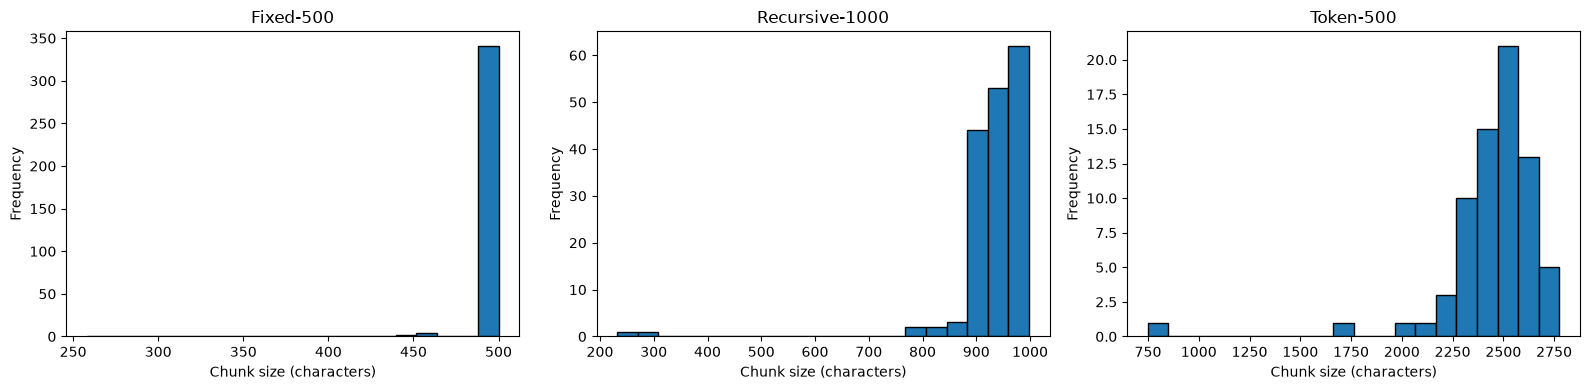


Fixed-500 boundary samples:
Chunk 0 ends with: 'orthy AI put forward in these Guidelines, \nalthoug' | clean ending: False
Chunk 1 ends with: 'arly 2020. \n \n \nThe AI HLEG is an independent expe' | clean ending: False
Chunk 2 ends with: 's. We wish to explicitly and warmly thank all thos' | clean ending: False

Recursive-1000 boundary samples:
Chunk 0 ends with: 'esented to the Eu ropean Commission in early 2020.' | clean ending: True
Chunk 1 ends with: 'ommission staff facilitated the preparation of the' | clean ending: False
Chunk 2 ends with: 'ements of Trustworthy AI                        14' | clean ending: False

Token-500 boundary samples:
Chunk 0 ends with: 'y of European Commission documents is regulated by' | clean ending: False
Chunk 1 ends with: ' list of ethical principles, by providing guidance' | clean ending: False
Chunk 2 ends with: 'non-discrimination and fairness, (6) environmental' | clean ending: False


In [94]:
# Compare the same source (the PDF) so the strategies are directly comparable.
fixed_500 = fixed_chunks(pdf_text, 500, 50)
recursive_1000 = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=50, separators=["\n\n", "\n", ". ", "? ", "! ", " ", ""]).split_text(pdf_text)
token_500 = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=500, chunk_overlap=50).split_text(pdf_text)

def char_stats(chunks):
    sizes = [len(c) for c in chunks]
    return {"Avg chunk size (chars)": round(sum(sizes)/len(sizes), 1),
            "Min": min(sizes), "Max": max(sizes), "# of chunks": len(sizes)}

comparison_table = pd.DataFrame({
    "Fixed-500": char_stats(fixed_500),
    "Recursive-1000": char_stats(recursive_1000),
    "Token-500": char_stats(token_500),
}).T
display(comparison_table)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (label, chunks) in zip(axes, [("Fixed-500", fixed_500), ("Recursive-1000", recursive_1000), ("Token-500", token_500)]):
    ax.hist([len(c) for c in chunks], bins=20, edgecolor="black")
    ax.set_title(label)
    ax.set_xlabel("Chunk size (characters)")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

for label, chunks in [("Fixed-500", fixed_500), ("Recursive-1000", recursive_1000), ("Token-500", token_500)]:
    print(f"\n{label} boundary samples:")
    for i, chunk in enumerate(chunks[:3]):
        ending = chunk[-50:]
        clean_ending = chunk.rstrip().endswith((".", "?", "!"))
        print(f"Chunk {i} ends with: {ending!r} | clean ending: {clean_ending}")


## Step 6. Visualize and compare results

The table and histograms compare three strategies on the same PDF text: fixed-size character chunking, recursive token-aware chunking, and token-based chunking. All sizes in the table are reported in characters so the rows can be compared directly.

The boundary samples show the final 50 characters of selected chunks and whether each chunk ends with sentence punctuation. A clean ending is a useful signal, but it is not a perfect measure: a sentence can end with a quote or bracket, and a punctuation mark can occur inside an abbreviation.

**Trade-offs:** Fixed-size chunking is simple and predictable, but it often cuts sentences. Recursive chunking usually preserves paragraphs and sentences better, while producing more variable chunk sizes. Token-based chunking gives the most reliable control over the model context window, but its character lengths vary and token boundaries do not necessarily match semantic boundaries. Semantic chunking can follow topic changes, but it is slower and requires an embedding model.

In [95]:
def chunk_text(chunk):
    return chunk.page_content if hasattr(chunk, "page_content") else str(chunk)

def pct_clean_boundaries(chunks):
    """Return the percentage of chunks ending with sentence punctuation."""
    if not chunks:
        return 0.0
    clean = sum(chunk_text(c).strip().endswith((".", "?", "!")) for c in chunks)
    return clean / len(chunks) * 100

def quality_row(text, source, strategy, chunks):
    return {"Source": source, "Strategy": strategy, "Chunks": len(chunks),
            "Clean endings (%)": round(pct_clean_boundaries(chunks), 1)}

quality_rows = []
for source, text in [("Podcast", podcast_text), ("PDF", pdf_text)]:
    fixed = fixed_chunks(text, 500, 50)
    recursive = RecursiveCharacterTextSplitter(
        chunk_size=500, chunk_overlap=50,
        separators=["\n\n", "\n", ". ", "? ", "! ", " ", ""]
    ).split_text(text)
    token = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=500, chunk_overlap=50).split_text(text)
    quality_rows.extend([quality_row(text, source, "Fixed-500", fixed),
                         quality_row(text, source, "Recursive-500", recursive),
                         quality_row(text, source, "Token-500", token)])

quality_comparison = pd.DataFrame(quality_rows).set_index(["Source", "Strategy"])
display(quality_comparison)


Chunks  Clean endings (%)
Source  Strategy                                
Podcast Fixed-500          37                5.4
        Recursive-500      37                2.7
        Token-500           8               25.0
PDF     Fixed-500         348                3.2
        Recursive-500     353               22.4
        Token-500          71                1.4

## Analyze chunk quality

The function `pct_clean_boundaries` measures the percentage of chunks whose final non-whitespace character is `.`, `?`, or `!`. The table compares fixed-size, recursive, and token-based chunking for both the podcast and the PDF using a 500-unit target and 50-unit overlap.

A higher clean-ending percentage suggests better boundary preservation, although it is only a proxy: punctuation can occur inside abbreviations, and a sentence may end with a quote or bracket. In general, recursive chunking should preserve context best because it tries paragraph and sentence boundaries before falling back to spaces or characters; fixed-size and token-based chunking control size more predictably but can cut through sentences.

In [96]:
recommendation_rows = []
for source, text in [("PDF", pdf_text), ("Podcast", podcast_text)]:
    strategy_chunks = {
        "Fixed-500": fixed_chunks(text, 500, 50),
        "Recursive-500": RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50, separators=["\n\n", "\n", ". ", "? ", "! ", " ", ""]).split_text(text),
        "Token-500": TokenTextSplitter(encoding_name="cl100k_base", chunk_size=500, chunk_overlap=50).split_text(text),
    }
    for strategy, chunks in strategy_chunks.items():
        sizes = [len(chunk_text(c)) for c in chunks]
        recommendation_rows.append({"Source": source, "Strategy": strategy,
            "Avg chars": round(sum(sizes)/len(sizes), 1), "Min": min(sizes),
            "Max": max(sizes), "Chunks": len(chunks),
            "Clean endings (%)": round(pct_clean_boundaries(chunks), 1)})

recommendation_table = pd.DataFrame(recommendation_rows).set_index(["Source", "Strategy"])
display(recommendation_table)


Avg chars   Min   Max  Chunks  Clean endings (%)
Source  Strategy                                                       
PDF     Fixed-500          498.0   258   500     348                3.2
        Recursive-500      443.2   132   498     353               22.4
        Token-500         2443.3   748  2776      71                1.4
Podcast Fixed-500          493.1   261   500      37                5.4
        Recursive-500      463.3   389   499      37                2.7
        Token-500         2267.0  1569  2498       8               25.0

## Chunking Strategy Recommendations

The summary table above uses the same 500-unit target and 50-unit overlap for both content types. The clean-ending percentage is a boundary-preservation signal; the earlier token and semantic cells provide additional evidence about model context and meaning-based grouping.

### For PDF Documents

**Recommended strategy:** Recursive character chunking.

**Reasoning:** PDFs usually contain paragraphs, headings, and section structure. Recursive splitting tries to keep those larger structures together before falling back to sentences and spaces. Start with **500–1000 tokens** and **50–100 tokens of overlap**; increase the size for long policy sections or passages that require more context. Token-based chunking is a strong alternative when the main constraint is the model context window.

### For Podcast Transcripts

**Recommended strategy:** Recursive character chunking, or semantic chunking when embedding-model cost is acceptable.

**Reasoning:** Transcripts are often long conversational blocks with inconsistent punctuation and few paragraph breaks. Recursive splitting can still use sentence boundaries, while semantic chunking can detect topic changes that punctuation misses. Start with **500–1000 tokens** and **50–100 tokens of overlap**; use semantic chunking for high-value retrieval over longer conversations.

### Trade-offs Summary

| Strategy | Pros | Cons | Best for |
|---|---|---|---|
| Fixed-size | Simple, fast, predictable size | Often breaks sentences and structure | Uniform text and quick baselines |
| Recursive | Preserves paragraphs and sentence boundaries better | More configuration; sizes are less uniform | Structured PDFs and general-purpose RAG |
| Token-based | Precise control of LLM context windows | Requires a tokenizer; token boundaries are not semantic | LLM prompts and embedding pipelines |
| Semantic | Groups text by meaning and topic changes | Slower, model-dependent, computationally expensive | Complex transcripts and topic-rich content |